# 🚗 AutoWorth AI — Used Car Price & Deal Advisor


The regression workflow:
data loading → combining → cleaning → EDA → feature engineering → leakage-safe preprocessing → 4 regression models → evaluation → overfitting check → hyperparameter tuning → final test evaluation → feature importance → Smart Deal Advisor.




In [1]:
# 1. Imports and configuration
import os, zipfile, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
REFERENCE_YEAR = 2024   # fixed reference year used for Car Age
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## 2. Load and combine the manufacturer datasets

The supplied archive contains nine main manufacturer datasets:

Audi, BMW, Ford, Hyundai, Mercedes, Skoda, Toyota, Vauxhall and Volkswagen.




In [2]:
# Find the ZIP in Colab or in the local project folder
zip_candidates = [
    "/content/archive (9).zip",
    "/content/archive.zip",
    "data/archive.zip"
]
zip_path = next((p for p in zip_candidates if os.path.exists(p)), None)

if zip_path is None:
    from google.colab import files
    uploaded = files.upload()
    zip_path = next(iter(uploaded))

extract_dir = "used_car_data"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

files = sorted(glob.glob(os.path.join(extract_dir, "*.csv")))
files


['used_car_data/audi.csv',
 'used_car_data/bmw.csv',
 'used_car_data/cclass.csv',
 'used_car_data/focus.csv',
 'used_car_data/ford.csv',
 'used_car_data/hyundi.csv',
 'used_car_data/merc.csv',
 'used_car_data/skoda.csv',
 'used_car_data/toyota.csv',
 'used_car_data/unclean cclass.csv',
 'used_car_data/unclean focus.csv',
 'used_car_data/vauxhall.csv',
 'used_car_data/vw.csv']

In [3]:
# Load the nine manufacturer-level files and create Make before combining
manufacturer_files = {
    "audi.csv": "Audi",
    "bmw.csv": "BMW",
    "ford.csv": "Ford",
    "hyundi.csv": "Hyundai",
    "merc.csv": "Mercedes",
    "skoda.csv": "Skoda",
    "toyota.csv": "Toyota",
    "vauxhall.csv": "Vauxhall",
    "vw.csv": "Volkswagen",
}

frames = []
for filename, make in manufacturer_files.items():
    path = os.path.join(extract_dir, filename)
    temp = pd.read_csv(path)
    temp["Make"] = make
    frames.append(temp)
    print(f"{make:12s} -> {temp.shape}")

df = pd.concat(frames, ignore_index=True)

# Standardize column names
df = df.rename(columns={"tax(£)": "tax", "fuelType": "fuel_type"})
df.columns = [c.strip().lower() for c in df.columns]

print("Combined shape:", df.shape)
display(df.head())


Audi         -> (10668, 10)
BMW          -> (10781, 10)
Ford         -> (17965, 10)
Hyundai      -> (4860, 10)
Mercedes     -> (13119, 10)
Skoda        -> (6267, 10)
Toyota       -> (6738, 10)
Vauxhall     -> (13632, 10)
Volkswagen   -> (15157, 10)
Combined shape: (99187, 11)


,model,year,price,transmission,mileage,fuel_type,tax,mpg,enginesize,make,tax
0,A1,2017,12500,Manual,15735,Petrol,150.0,55.4,1.4,Audi,NaN
1,A6,2016,16500,Automatic,36203,Diesel,20.0,64.2,2.0,Audi,NaN
2,A1,2016,11000,Manual,29946,Petrol,30.0,55.4,1.4,Audi,NaN
3,A4,2017,16800,Automatic,25952,Diesel,145.0,67.3,2.0,Audi,NaN
4,A3,2019,17300,Manual,1998,Petrol,145.0,49.6,1.0,Audi,NaN


### Dataset Overview




*   The nine manufacturer datasets were combined into one dataset.

*   A `Make` column was added to identify the manufacturer of each car, and the Hyundai tax column was standardized so that the datasets could be combined consistently.

The target variable for this project is `price`.

In [4]:
# 3. Initial inspection
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())

display(df.describe(include="all").T)

for col in ["make", "model", "transmission", "fuel_type"]:
    print("\n", col)
    print(df[col].value_counts(dropna=False).head(20))


Shape: (99187, 11)


,dtype
model,object
year,int64
price,int64
transmission,object
mileage,int64
fuel_type,object
tax,float64
mpg,float64
enginesize,float64
make,object


,missing_values
model,0
year,0
price,0
transmission,0
mileage,0
fuel_type,0
tax,4860
mpg,0
enginesize,0
make,0


Duplicate rows: 1475


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
model,99187,195,Fiesta,6557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,99187.0,NaN,NaN,NaN,2017.087723,2.123934,1970.0,2016.0,2017.0,2019.0,2060.0
price,99187.0,NaN,NaN,NaN,16805.347656,9866.773417,450.0,9999.0,14495.0,20870.0,159999.0
transmission,99187,4,Manual,56445,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,99187.0,NaN,NaN,NaN,23058.914213,21148.523721,1.0,7425.0,17460.0,32339.0,323000.0
fuel_type,99187,5,Petrol,54928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tax,94327.0,NaN,NaN,NaN,120.256183,63.404805,0.0,125.0,145.0,145.0,580.0
mpg,99187.0,NaN,NaN,NaN,55.166825,16.138522,0.3,47.1,54.3,62.8,470.8
enginesize,99187.0,NaN,NaN,NaN,1.66328,0.557646,0.0,1.2,1.6,2.0,6.6
make,99187,9,Ford,17965,NaN,NaN,NaN,NaN,NaN,NaN,NaN



 make
make
Ford          17965
Volkswagen    15157
Vauxhall      13632
Mercedes      13119
BMW           10781
Audi          10668
Toyota         6738
Skoda          6267
Hyundai        4860
Name: count, dtype: int64

 model
model
Fiesta      6557
Golf        4863
Focus       4588
C Class     3747
Corsa       3441
Polo        3287
Astra       2805
A Class     2561
3 Series    2443
Kuga        2225
Mokka X     2127
Yaris       2122
1 Series    1969
Aygo        1961
E Class     1953
A3          1929
Tiguan      1765
Fabia       1571
Octavia     1477
Q3          1417
Name: count, dtype: int64

 transmission
transmission
Manual       56445
Semi-Auto    22677
Automatic    20056
Other            9
Name: count, dtype: int64

 fuel_type
fuel_type
Petrol      54928
Diesel      40928
Hybrid       3078
Other         247
Electric        6
Name: count, dtype: int64


In [5]:
print("Total rows:", len(df))
print("Missing Make:", df["make"].isna().sum())

Total rows: 99187
Missing Make: 0


In [6]:
df[df["make"].isna()].head()

,model,year,price,transmission,mileage,fuel_type,tax,mpg,enginesize,make,tax


In [7]:
print(df["make"].value_counts(dropna=False))

make
Ford          17965
Volkswagen    15157
Vauxhall      13632
Mercedes      13119
BMW           10781
Audi          10668
Toyota         6738
Skoda          6267
Hyundai        4860
Name: count, dtype: int64


In [8]:
missing = df.isna().sum().sort_values(ascending=False)

print(missing)

tax             94327
tax              4860
model               0
price               0
year                0
mileage             0
transmission        0
fuel_type           0
mpg                 0
enginesize          0
make                0
dtype: int64


In [9]:
# Find the positions of the two tax columns
tax_positions = [
    i for i, col in enumerate(df.columns)
    if col == "tax"
]

print("Tax column positions:", tax_positions)

Tax column positions: [6, 10]


In [10]:
# Display both tax columns for Hyundai
hyundai_rows = df["make"] == "Hyundai"

display(
    df.loc[hyundai_rows].iloc[:, tax_positions].head(10)
)

,tax,tax
39414,NaN,145.0
39415,NaN,235.0
39416,NaN,30.0
39417,NaN,20.0
39418,NaN,160.0
39419,NaN,20.0
39420,NaN,30.0
39421,NaN,125.0
39422,NaN,145.0
39423,NaN,30.0


In [11]:
# Display both tax columns for a non-Hyundai manufacturer
ford_rows = df["make"] == "Ford"

display(
    df.loc[ford_rows].iloc[:, tax_positions].head(10)
)

,tax,tax
21449,150.0,NaN
21450,150.0,NaN
21451,150.0,NaN
21452,145.0,NaN
21453,145.0,NaN
21454,145.0,NaN
21455,145.0,NaN
21456,145.0,NaN
21457,145.0,NaN
21458,145.0,NaN


### note:
⏬Here we want to investigate for the tax columns and make sure to combine them into one column.

In [12]:
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Shape: (99187, 11)
Columns:
['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'tax', 'mpg', 'enginesize', 'make', 'tax']


In [13]:
# Find all columns named "tax"
tax_columns = df.loc[:, df.columns == "tax"]

print("Number of tax columns:", tax_columns.shape[1])
print(tax_columns.head())

Number of tax columns: 2
     tax  tax
0  150.0  NaN
1   20.0  NaN
2   30.0  NaN
3  145.0  NaN
4  145.0  NaN


In [14]:
# Find all tax columns
tax_columns = df.loc[:, df.columns == "tax"]

# If there are two tax columns, combine them
if tax_columns.shape[1] == 2:
    combined_tax = tax_columns.iloc[:, 0].combine_first(tax_columns.iloc[:, 1])

# If there is already only one tax column, keep it
elif tax_columns.shape[1] == 1:
    combined_tax = tax_columns.iloc[:, 0]

else:
    raise ValueError("Unexpected number of tax columns.")

# Remove all existing tax columns
df = df.loc[:, df.columns != "tax"].copy()

# Add the final single tax column
df["tax"] = combined_tax

print("Tax column fixed successfully!")

Tax column fixed successfully!


In [15]:
print("Shape:", df.shape)
print("Number of columns:", len(df.columns))
print(df.columns.tolist())

Shape: (99187, 10)
Number of columns: 10
['model', 'year', 'price', 'transmission', 'mileage', 'fuel_type', 'mpg', 'enginesize', 'make', 'tax']


In [16]:
print(df.columns.tolist().count("tax"))

1


In [17]:
print("Duplicate rows:", df.duplicated().sum())
print("\nMissing values:")
print(df.isnull().sum())

Duplicate rows: 1475

Missing values:
model           0
year            0
price           0
transmission    0
mileage         0
fuel_type       0
mpg             0
enginesize      0
make            0
tax             0
dtype: int64


## 4. Data cleaning decisions

### There are duplicated rows.. we need to investigate them first using cleaning.

In [18]:
duplicates = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:", len(duplicates))

display(
    duplicates.sort_values(
        by=["make", "model", "year", "price"]
    ).head(20)
)

Total rows involved in duplicates: 2457


,model,year,price,transmission,mileage,fuel_type,mpg,enginesize,make,tax
4000,A1,2019,19990,Manual,2348,Petrol,50.4,1.0,Audi,145.0
5036,A1,2019,19990,Manual,2348,Petrol,50.4,1.0,Audi,145.0
4469,A1,2019,20595,Manual,6000,Petrol,47.9,1.0,Audi,145.0
4522,A1,2019,20595,Manual,6000,Petrol,47.9,1.0,Audi,145.0
4826,A1,2019,20595,Manual,6000,Petrol,47.9,1.0,Audi,145.0
5169,A1,2019,20595,Manual,6000,Petrol,47.9,1.0,Audi,145.0
7430,A1,2019,22000,Semi-Auto,7500,Petrol,40.9,2.0,Audi,150.0
7431,A1,2019,22000,Semi-Auto,7500,Petrol,40.9,2.0,Audi,150.0
8600,A1,2019,22450,Automatic,6481,Petrol,40.9,2.0,Audi,150.0
8601,A1,2019,22450,Automatic,6481,Petrol,40.9,2.0,Audi,150.0


In [19]:
duplicate_counts = (
    duplicates["make"]
    .value_counts()
)

print(duplicate_counts)

make
Vauxhall      509
Volkswagen    481
Mercedes      425
Ford          302
Audi          185
BMW           179
Skoda         155
Hyundai       147
Toyota         74
Name: count, dtype: int64


In [20]:
print(
    "Number of exact duplicate rows:",
    df.duplicated().sum()
)

Number of exact duplicate rows: 1475


### Removing the exact duplicate rows
Now it is reasonable to remove them because keeping identical copies - repeated observations would give extra weight during model training.


In [21]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (97712, 10)


The duplicate rows were removed. The dataset now contains 97,712 unique car records.

### We'll investigate the numerical variables:

price,
year,
mileage,
tax,
mpg,
enginesize.


### * We'll look at their * :


minimum,
maximum,
quartiles,
unusual values.

In [22]:
print("Minimum values:")
display(df[["year", "price", "mileage", "tax", "mpg", "enginesize"]].min())

print("\nMaximum values:")
display(df[["year", "price", "mileage", "tax", "mpg", "enginesize"]].max())

Minimum values:


,0
year,1970.0
price,450.0
mileage,1.0
tax,0.0
mpg,0.3
enginesize,0.0



Maximum values:


,0
year,2060.0
price,159999.0
mileage,323000.0
tax,580.0
mpg,470.8
enginesize,6.6


### Checking for the suspecious values:

In [23]:
# Check suspicious year values
print("Cars with year > 2024:")
display(df[df["year"] > 2024][["make", "model", "year", "price"]])

Cars with year > 2024:


,make,model,year,price
38801,Ford,Fiesta,2060,6495


In [24]:
# Check very low MPG values
print("Cars with mpg < 10:")
display(df[df["mpg"] < 10][["make", "model", "year", "mpg", "enginesize"]].head(20))

# Check very high MPG values
print("Cars with mpg > 150:")
display(df[df["mpg"] > 150][["make", "model", "year", "mpg", "enginesize"]].head(20))

Cars with mpg < 10:


,make,model,year,mpg,enginesize
11797,BMW,X3,2020,5.5,2.0
12616,BMW,X3,2020,5.5,2.0
13632,BMW,3 Series,2019,8.8,2.0
15459,BMW,3 Series,2019,8.8,2.0
15976,BMW,3 Series,2019,8.8,2.0
16417,BMW,3 Series,2019,8.8,2.0
16589,BMW,X3,2020,5.5,2.0
16629,BMW,X3,2020,5.5,2.0
16655,BMW,X3,2020,5.5,2.0
16945,BMW,3 Series,2019,8.8,2.0


Cars with mpg > 150:


,make,model,year,mpg,enginesize
2534,Audi,Q7,2017,156.9,3.0
3090,Audi,A3,2015,188.3,1.4
4235,Audi,A3,2015,188.3,1.4
4463,Audi,A3,2014,188.3,1.4
4524,Audi,A3,2015,176.6,1.4
4834,Audi,A3,2014,188.3,1.4
5597,Audi,Q7,2016,156.9,3.0
5648,Audi,A3,2016,176.6,1.4
5909,Audi,Q7,2016,156.9,3.0
8229,Audi,A3,2016,176.6,1.4


In [25]:
# Check cars with engine size equal to 0
print("Cars with enginesize = 0:", (df["enginesize"] == 0).sum())

display(
    df[df["enginesize"] == 0][
        ["make", "model", "year", "price", "enginesize"]
    ].head(20)
)

Cars with enginesize = 0: 268


,make,model,year,price,enginesize
7425,Audi,Q5,2019,44790,0.0
7426,Audi,Q3,2019,32788,0.0
7436,Audi,Q3,2020,29944,0.0
7437,Audi,Q3,2020,33333,0.0
7438,Audi,Q3,2020,29944,0.0
7439,Audi,Q3,2020,37990,0.0
7441,Audi,Q5,2020,49790,0.0
7462,Audi,Q3,2019,31888,0.0
7465,Audi,Q2,2020,24988,0.0
7466,Audi,A3,2017,17390,0.0


### Investigating Suspicious Values

Investigation first before deciding whether to remove them.

I found one car with an invalid year value of 2060. Since this value was clearly unrealistic for a used car dataset, I corrected it to 2020, which is more consistent with similar vehicles in the dataset.
And also found 2 cars with a year of 1970. These values were unrealistic for the cars in the dataset, so I removed these two records rather than using an estimated year.

After removing them, the dataset contains **97,710 car records**.





I also investigated unusual MPG values and engine sizes equal to zero. These values were mainly associated with hybrid or electric vehicles and therefore may represent genuine vehicle characteristics rather than errors.

For this reason, these observations were retained.

In [26]:
# Correct the invalid future year
df.loc[df["year"] == 2060, "year"] = 2020

In [27]:
print(df["year"].max())

2020


In [28]:
df = df[df["year"] != 1970].reset_index(drop=True)

print("Dataset shape after removing unrealistic years:", df.shape)

Dataset shape after removing unrealistic years: (97710, 10)


## 5. Exploratory Data Analysis


After cleaning the dataset, I performed exploratory data analysis to understand the distribution of car prices and the relationships between price and other important features:



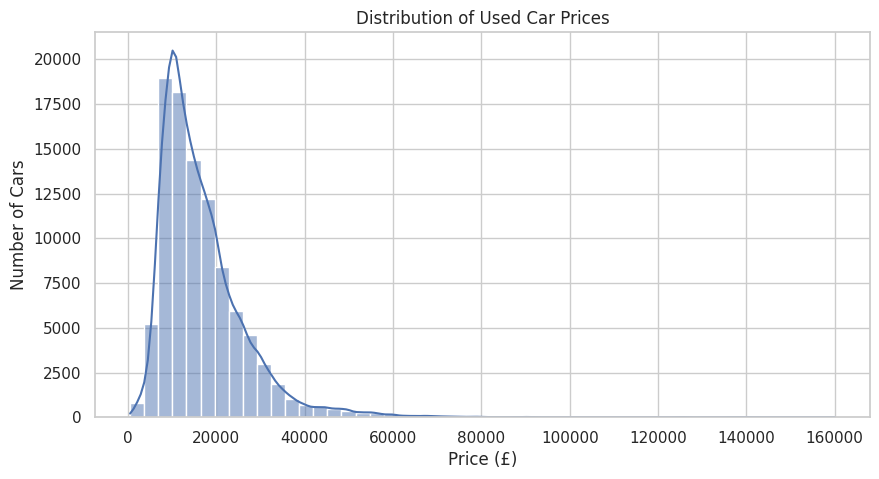

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(df["price"], bins=50, kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Cars")
plt.show()

### Conclusion

The price distribution shows that most used cars have relatively lower prices, while fewer cars have very high prices. This means the distribution is right-skewed, with some expensive cars creating a long tail.


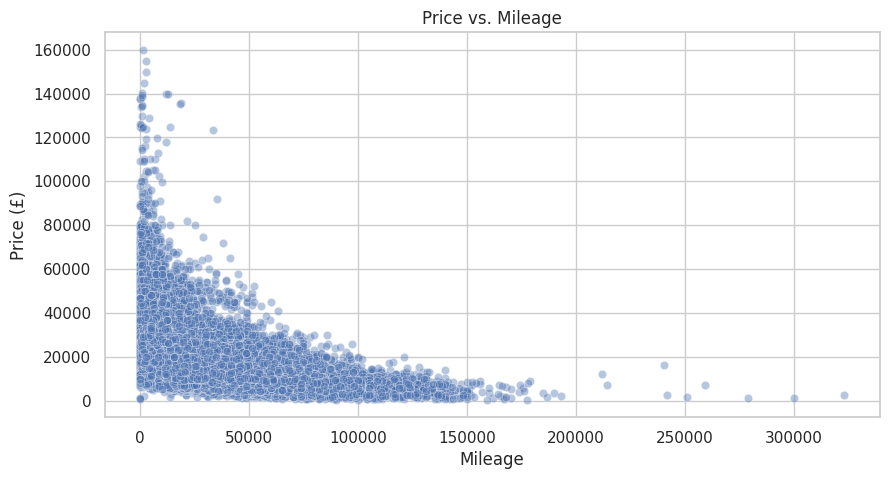

In [30]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="mileage",
    y="price",
    alpha=0.4
)

plt.title("Price vs. Mileage")
plt.xlabel("Mileage")
plt.ylabel("Price (£)")
plt.show()

### Conclusion

The scatter plot shows that cars with higher mileage generally tend to have lower prices.

However, the points are spread out, which means mileage is not the only factor affecting car prices.
Other factors such as the car's year, manufacturer, model, and engine size can also affect the price.


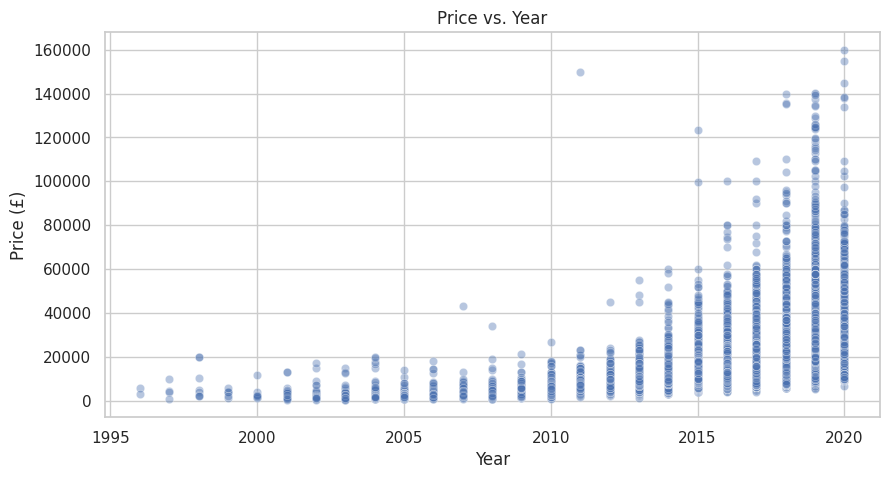

In [31]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="year",
    y="price",
    alpha=0.4
)

plt.title("Price vs. Year")
plt.xlabel("Year")
plt.ylabel("Price (£)")
plt.show()

### Conclusion


The graph shows that newer cars generally have higher prices, while older cars tend to have lower prices.

There is some variation in price for cars from the same year, which shows that other factors such as mileage, manufacturer, model, and engine size also affect the price.

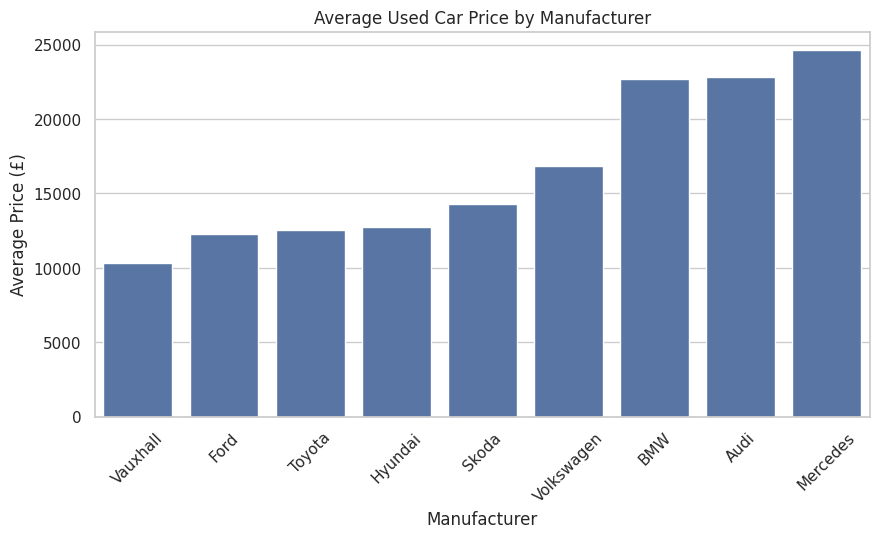

In [32]:
avg_price = df.groupby("make")["price"].mean().sort_values()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=avg_price.index,
    y=avg_price.values
)

plt.title("Average Used Car Price by Manufacturer")
plt.xlabel("Manufacturer")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45)
plt.show()

### Conclusion

The average price differs between manufacturers. Vauxhall has the lowest average price, while Mercedes has the highest average price in the dataset. This suggests that the manufacturer is an important factor that can affect used car prices.


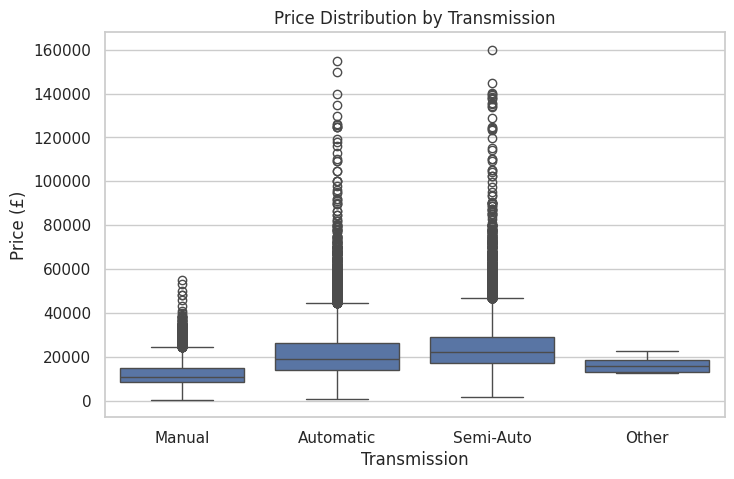

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="transmission",
    y="price"
)

plt.title("Price Distribution by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Price (£)")
plt.show()

### Conclusion

The boxplot shows that Semi-Auto cars have the highest median price, while Manual cars have the lowest median price.

There are also many outliers in all transmission categories, showing that some cars have much higher or lower prices than most cars in the same transmission group.


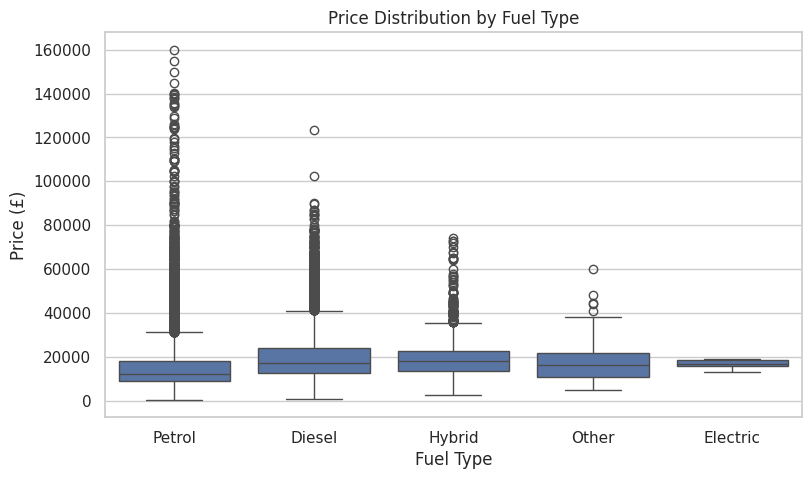

In [34]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="fuel_type",
    y="price"
)

plt.title("Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Price (£)")
plt.show()

### Conclusion

The boxplot shows that Hybrid cars have the highest median price, while Petrol cars have the lowest median price.

Some fuel types have many outliers, showing that prices can vary significantly within the same fuel type. The Electric category does not show any visible outliers in the graph.


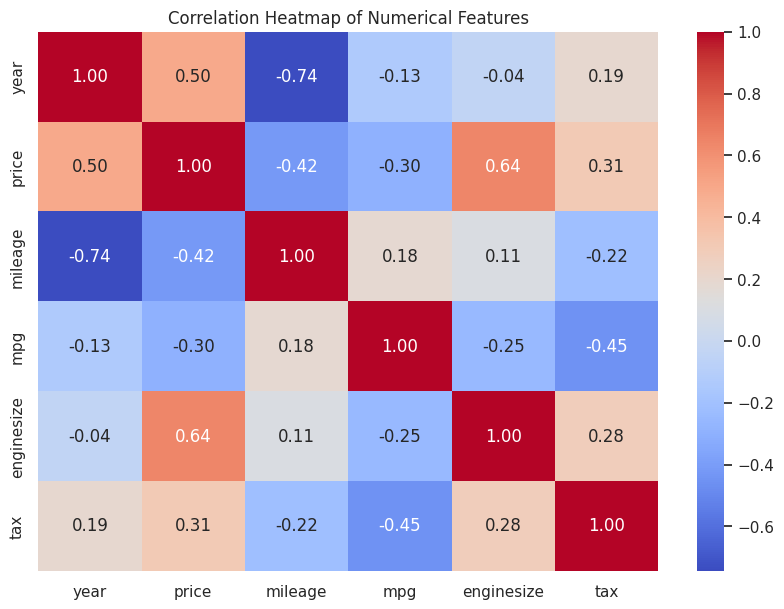

In [35]:
plt.figure(figsize=(10, 7))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Conclusion

The correlation results show that engine size has the strongest positive relationship with price. Year also has a positive relationship with price, while mileage has a negative relationship. Tax and MPG have weaker relationships with price.

(Overall, these results show that several numerical features may help the model predict used car prices).


# Feature Engineering

Helps the ML model make better predictions.




#### 1. Car Age

I created a new feature called `car_age` to represent the age of each car. It is calculated by subtracting the car's year from the reference year. Older cars will have a higher `car_age` value, while newer cars will have a lower value.

In [36]:
df["car_age"] = REFERENCE_YEAR - df["year"]

print(df[["year", "car_age"]].head())

   year  car_age
0  2017        7
1  2016        8
2  2016        8
3  2017        7
4  2019        5


#### 2. Mileage per Year

 `mileage_per_year` shows the average mileage driven by a car per year. This feature can help the model understand how heavily a car has been used, instead of looking only at its total mileage.


In [37]:
df["mileage_per_year"] = df["mileage"] / df["car_age"].replace(0, 1)

print(df[["mileage", "car_age", "mileage_per_year"]].head())

   mileage  car_age  mileage_per_year
0    15735        7       2247.857143
1    36203        8       4525.375000
2    29946        8       3743.250000
3    25952        7       3707.428571
4     1998        5        399.600000


#### 3. Engine Size per Age

`engine_size_per_age` to help identify differences between newer and older cars with different engine sizes.


In [38]:
df["engine_size_per_age"] = df["enginesize"] / df["car_age"].replace(0, 1)

print(df[["enginesize", "car_age", "engine_size_per_age"]].head())

   enginesize  car_age  engine_size_per_age
0         1.4        7             0.200000
1         2.0        8             0.250000
2         1.4        8             0.175000
3         2.0        7             0.285714
4         1.0        5             0.200000


In [39]:
# Check the engineered features
engineered_features = [
    "car_age",
    "mileage_per_year",
    "engine_size_per_age"
]

print("Missing values:")
print(df[engineered_features].isna().sum())

print("\nInfinite values:")
print(np.isinf(df[engineered_features]).sum())

print("\nSummary:")
display(df[engineered_features].describe())

Missing values:
car_age                0
mileage_per_year       0
engine_size_per_age    0
dtype: int64

Infinite values:
car_age                0
mileage_per_year       0
engine_size_per_age    0
dtype: int64

Summary:


,car_age,mileage_per_year,engine_size_per_age
count,97710.000000,97710.000000,97710.000000
mean,6.932576,2995.566476,0.259238
std,2.107859,2181.070117,0.115856
min,4.000000,0.043478,0.000000
25%,5.000000,1350.031250,0.175000
50%,7.000000,2631.775000,0.233333
75%,8.000000,4177.593750,0.300000
max,28.000000,30061.750000,1.300000


## Data Preparation for Modeling

Before building the machine learning models, the dataset was divided into features and target variables.

The target variable is `price`, which represents the value the model will predict. The remaining columns are used as input features.

The original `year` column was removed because the engineered feature `car_age` provides a more meaningful representation of the vehicle's age.


In [40]:
# Define target variable
y = df["price"]

# Define feature variables
X = df.drop(columns=["price", "model", "year"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (97710, 10)
Target shape: (97710,)


,transmission,mileage,fuel_type,mpg,enginesize,make,tax,car_age,mileage_per_year,engine_size_per_age
0,Manual,15735,Petrol,55.4,1.4,Audi,150.0,7,2247.857143,0.200000
1,Automatic,36203,Diesel,64.2,2.0,Audi,20.0,8,4525.375000,0.250000
2,Manual,29946,Petrol,55.4,1.4,Audi,30.0,8,3743.250000,0.175000
3,Automatic,25952,Diesel,67.3,2.0,Audi,145.0,7,3707.428571,0.285714
4,Manual,1998,Petrol,49.6,1.0,Audi,145.0,5,399.600000,0.200000


## 6. Train / validation / test split

We use **70% training, 15% validation and 15% test**.

The test set is held back until the final model is selected. All preprocessing is fitted inside a pipeline on the training data only, preventing data leakage.


In [41]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

# Second split: divide the 30% into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (68397, 10) (68397,)
Validation set: (14656, 10) (14656,)
Test set: (14657, 10) (14657,)


Before training, we need to know which columns are:

Numerical (can be used directly (or scaled)) or
Categorical ( need encoding ).

In [42]:
# Check feature data types
X_train.info()

# Show categorical columns
categorical_cols = X_train.select_dtypes(include=["object"]).columns
print("Categorical columns:", list(categorical_cols))

# Show numerical columns
numerical_cols = X_train.select_dtypes(exclude=["object"]).columns
print("Numerical columns:", list(numerical_cols))

<class 'pandas.core.frame.DataFrame'>
Index: 68397 entries, 33060 to 15795
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transmission         68397 non-null  object 
 1   mileage              68397 non-null  int64  
 2   fuel_type            68397 non-null  object 
 3   mpg                  68397 non-null  float64
 4   enginesize           68397 non-null  float64
 5   make                 68397 non-null  object 
 6   tax                  68397 non-null  float64
 7   car_age              68397 non-null  int64  
 8   mileage_per_year     68397 non-null  float64
 9   engine_size_per_age  68397 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 5.7+ MB
Categorical columns: ['transmission', 'fuel_type', 'make']
Numerical columns: ['mileage', 'mpg', 'enginesize', 'tax', 'car_age', 'mileage_per_year', 'engine_size_per_age']


# Preprocessing Pipeline


Scaling numerical features using StandardScaler.

**Encoding categorical features** using OneHotEncoder.

Then combining everything automatically before training.

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Define preprocessing for numerical columns
numeric_transformer = StandardScaler()

# Define preprocessing for categorical columns
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully ✅")

Preprocessing pipeline created successfully ✅


I will fit it only on the training data and transform the training, validation, and test sets.

(Because we don't want information from the validation/test sets to leak into the training process).

### Applying the Preprocessing

In [44]:
# Fit the preprocessor only on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Validation data after preprocessing:", X_val_processed.shape)
print("Test data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (68397, 25)
Validation data after preprocessing: (14656, 25)
Test data after preprocessing: (14657, 25)


# **Training regression models**


The model is trained using the preprocessed training data and evaluated on the validation data using **MAE, MSE, RMSE, and R²**.




### Linear Regression Model.


In [45]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_train)

# Predict prices on the validation set
y_val_pred = linear_model.predict(X_val_processed)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_val_pred)
mse = mean_squared_error(y_val, y_val_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_val_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

Linear Regression Results
-------------------------
MAE: 2601.2999383413953
MSE: 17526966.78442482
RMSE: 4186.52203916626
R²: 0.8222746379891148


### Decision Tree Regressor

In [46]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Decision Tree model
dt_model = DecisionTreeRegressor(
    random_state=RANDOM_STATE,
    max_depth=20
)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Predict prices on the validation set
y_val_pred_dt = dt_model.predict(X_val_processed)

# Calculate evaluation metrics
mae_dt = mean_absolute_error(y_val, y_val_pred_dt)
mse_dt = mean_squared_error(y_val, y_val_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_val, y_val_pred_dt)

print("Decision Tree Results")
print("---------------------")
print("MAE:", mae_dt)
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R²:", r2_dt)

Decision Tree Results
---------------------
MAE: 1602.915939080869
MSE: 8415415.815139117
RMSE: 2900.93361094995
R²: 0.9146667623318138


###  Random Forest Regressor



In [47]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict prices on the validation set
y_val_pred_rf = rf_model.predict(X_val_processed)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_val, y_val_pred_rf)
mse_rf = mean_squared_error(y_val, y_val_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_val, y_val_pred_rf)

print("Random Forest Results")
print("---------------------")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

Random Forest Results
---------------------
MAE: 1370.5217694548446
MSE: 5507793.977545899
RMSE: 2346.868973237726
R²: 0.9441503660855576


### Gradient Boosting Regressor


In [48]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

# Train the model
gb_model.fit(X_train_processed, y_train)

# Predict prices on the validation set
y_val_pred_gb = gb_model.predict(X_val_processed)

# Calculate evaluation metrics
mae_gb = mean_absolute_error(y_val, y_val_pred_gb)
mse_gb = mean_squared_error(y_val, y_val_pred_gb)
rmse_gb = np.sqrt(mse_gb)
r2_gb = r2_score(y_val, y_val_pred_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE:", mae_gb)
print("MSE:", mse_gb)
print("RMSE:", rmse_gb)
print("R²:", r2_gb)

Gradient Boosting Results
-------------------------
MAE: 2125.3425192272307
MSE: 10748309.031171741
RMSE: 3278.4613816807023
R²: 0.8910109697208197


### Comparing the Regression Models


The 4 models were compared using MAE, MSE, RMSE, and R².

Random Forest achieved the lowest error values (especially MAE of 1370) and the highest R² score of **0.9442** on the validation set.

Therefore it will be used for further tuning and final evaluation on the test set.


### **Overfitting Check**

I compared regression models' performance on the training set with their performance on the validation set.

A **large** difference between training and validation performance can indicate overfitting, while a **smaller** difference suggests that the model generalizes better to unseen data.


In [49]:
# Overfitting Check

# Predictions on the training set
y_train_pred_lr = linear_model.predict(X_train_processed)
y_train_pred_dt = dt_model.predict(X_train_processed)
y_train_pred_rf = rf_model.predict(X_train_processed)
y_train_pred_gb = gb_model.predict(X_train_processed)

# Calculate Training R²
train_r2_lr = r2_score(y_train, y_train_pred_lr)
train_r2_dt = r2_score(y_train, y_train_pred_dt)
train_r2_rf = r2_score(y_train, y_train_pred_rf)
train_r2_gb = r2_score(y_train, y_train_pred_gb)

# Calculate Validation R²
val_r2_lr = r2_score(y_val, y_val_pred)
val_r2_dt = r2_score(y_val, y_val_pred_dt)
val_r2_rf = r2_score(y_val, y_val_pred_rf)
val_r2_gb = r2_score(y_val, y_val_pred_gb)

print("Overfitting Check")
print("-----------------")
print("Linear Regression - Train R²:", train_r2_lr,
      "| Validation R²:", val_r2_lr)

print("Decision Tree     - Train R²:", train_r2_dt,
      "| Validation R²:", val_r2_dt)

print("Random Forest     - Train R²:", train_r2_rf,
      "| Validation R²:", val_r2_rf)

print("Gradient Boosting - Train R²:", train_r2_gb,
      "| Validation R²:", val_r2_gb)

Overfitting Check
-----------------
Linear Regression - Train R²: 0.8175117251838326 | Validation R²: 0.8222746379891148
Decision Tree     - Train R²: 0.9912575462845843 | Validation R²: 0.9146667623318138
Random Forest     - Train R²: 0.9908486777326573 | Validation R²: 0.9441503660855576
Gradient Boosting - Train R²: 0.8944591376571259 | Validation R²: 0.8910109697208197


### Overfitting Check Results

 Decision Tree and Random Forest have a noticeable difference between their training and validation R² scores, which indicates some overfitting.

 The Decision Tree has the largest gap, while the Random Forest has a smaller gap and better validation performance.

Since the Random Forest achieved the highest validation R²  and the lowest validation MAE, I will tune the Random Forest hyperparameters to try to improve its performance and reduce overfitting.


# Hyperparameter tuning



In [50]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Create the base Random Forest
rf_base = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Hyperparameters to test
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

# Randomized search
rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
rf_search.fit(X_train_processed, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest CV MAE:")
print(-rf_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20}

Best CV MAE:
1400.8987170964676


In [51]:
# Get the best tuned Random Forest
tuned_rf = rf_search.best_estimator_

# Predict on the validation set
y_val_pred_tuned = tuned_rf.predict(X_val_processed)

# Calculate validation metrics
mae_tuned = mean_absolute_error(y_val, y_val_pred_tuned)
mse_tuned = mean_squared_error(y_val, y_val_pred_tuned)
rmse_tuned = np.sqrt(mse_tuned)
r2_tuned = r2_score(y_val, y_val_pred_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", mae_tuned)
print("MSE:", mse_tuned)
print("RMSE:", rmse_tuned)
print("R²:", r2_tuned)

Tuned Random Forest Results
---------------------------
MAE: 1338.4299251293005
MSE: 5302247.339902995
RMSE: 2302.660925951321
R²: 0.9462346314940862


In [52]:
# Overfitting Check for Tuned Random Forest

y_train_pred_tuned = tuned_rf.predict(X_train_processed)

train_r2_tuned = r2_score(y_train, y_train_pred_tuned)
val_r2_tuned = r2_score(y_val, y_val_pred_tuned)

print("Tuned Random Forest Overfitting Check")
print("-------------------------------------")
print("Training R²:", train_r2_tuned)
print("Validation R²:", val_r2_tuned)
print("R² Gap:", train_r2_tuned - val_r2_tuned)

Tuned Random Forest Overfitting Check
-------------------------------------
Training R²: 0.9872799744837886
Validation R²: 0.9462346314940862
R² Gap: 0.041045342989702416


### Tuned Random Forest Overfitting Check

After tuning the Random Forest, the gap decreased from approximately **0.0467 to 0.0410**. At the same time, the validation R² improved from **0.9442 to 0.9462**.

This shows that the tuned Random Forest has better validation performance and a slightly smaller overfitting gap.

Although there is still some difference between training and validation performance, the model generalizes better than the original Random Forest.


### **Final Model Evaluation**

Evaluating the final model on the test set.

The test set was not used during model training, validation, or hyperparameter tuning.

This provides a final evaluation of how well the model performs on unseen used-car data.


In [53]:
# Final evaluation on the test set

y_test_pred = tuned_rf.predict(X_test_processed)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print("Final Random Forest Test Results")
print("--------------------------------")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)
print("R²:", test_r2)

Final Random Forest Test Results
--------------------------------
MAE: 1353.9699809781737
MSE: 5459986.17458774
RMSE: 2336.661330742592
R²: 0.9443221808387301


### Final Model Evaluation Results


The test results are close to the validation results, which indicates that the model performs consistently on unseen data.

The R² of 0.9443 means that the model explains approximately **94.43% of the variation in used-car prices** in the test set.


# **Understanding The Model**

## Actual vs Predicted Price

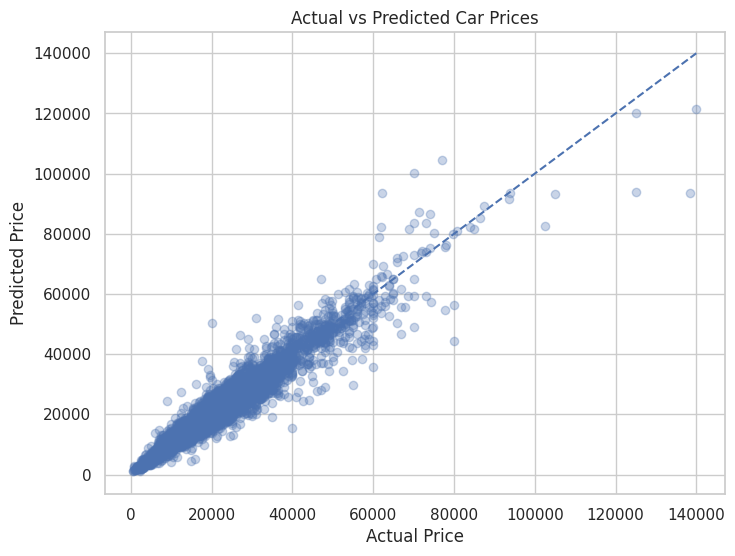

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.3)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

Most points should be relatively close to the diagonal line, which suggests that the model is performing well.

## Most Important Features

In [55]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance
importances = tuned_rf.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Most Important Features")
print("-------------------------------")
print(feature_importance_df.head(15))

Top 15 Most Important Features
-------------------------------
                     Feature  Importance
6   num__engine_size_per_age    0.774078
1                   num__mpg    0.071883
0               num__mileage    0.023983
8   cat__transmission_Manual    0.023774
5      num__mileage_per_year    0.020463
4               num__car_age    0.013266
16            cat__make_Audi    0.009389
3                   num__tax    0.008578
20        cat__make_Mercedes    0.008457
18            cat__make_Ford    0.008052
2            num__enginesize    0.007759
23        cat__make_Vauxhall    0.006342
17             cat__make_BMW    0.004175
15     cat__fuel_type_Petrol    0.003345
11     cat__fuel_type_Diesel    0.003327


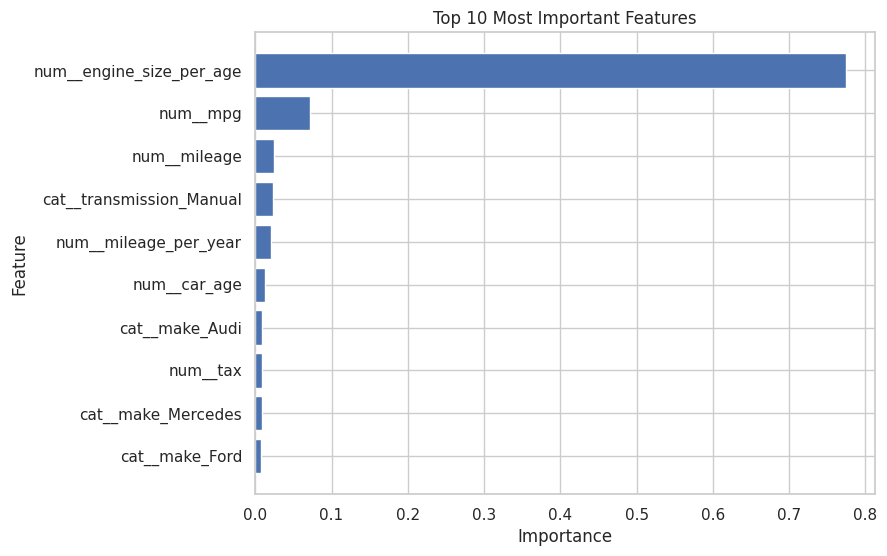

In [56]:
top_features = feature_importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Most Important Features")
plt.show()

## Investigation of Large Prediction Errors

In [57]:
# Find the predictions with the largest errors

error_analysis = X_test.copy()

error_analysis["Actual Price"] = y_test.values
error_analysis["Predicted Price"] = y_test_pred

error_analysis["Absolute Error"] = np.abs(
    y_test.values - y_test_pred
)

largest_errors = error_analysis.sort_values(
    by="Absolute Error",
    ascending=False
)

print("10 Predictions With the Largest Errors")
print("---------------------------------------")

display(largest_errors.head(10))

10 Predictions With the Largest Errors
---------------------------------------


,transmission,mileage,fuel_type,mpg,enginesize,make,tax,car_age,mileage_per_year,engine_size_per_age,Actual Price,Predicted Price,Absolute Error
52435,Semi-Auto,1000,Petrol,22.1,4.0,Mercedes,145.0,4,250.000000,1.000000,138439,93451.944444,44987.055556
49335,Semi-Auto,25317,Petrol,24.1,6.0,Mercedes,570.0,8,3164.625000,0.750000,79950,44508.696444,35441.303556
52841,Semi-Auto,1000,Petrol,22.1,4.0,Mercedes,145.0,4,250.000000,1.000000,62189,93451.944444,31262.944444
3342,Automatic,100,Petrol,24.1,5.2,Audi,145.0,5,20.000000,1.040000,125000,94025.523333,30974.476667
50116,Automatic,1829,Petrol,22.1,4.0,Mercedes,145.0,5,365.800000,0.800000,69995,100292.925000,30297.925000
11627,Automatic,11805,Hybrid,135.5,1.5,BMW,135.0,6,1967.500000,0.250000,19995,50228.171333,30233.171333
49898,Automatic,3012,Petrol,22.1,4.0,Mercedes,145.0,5,602.400000,0.800000,76989,104592.876667,27603.876667
55447,Automatic,34564,Diesel,44.8,2.1,Mercedes,145.0,7,4937.714286,0.300000,54990,29622.347161,25367.652839
53209,Automatic,2802,Diesel,52.3,2.9,Mercedes,140.0,6,467.000000,0.483333,59995,35639.953924,24355.046076
20429,Automatic,49000,Petrol,25.4,0.0,BMW,570.0,8,6125.000000,0.000000,39948,15612.140764,24335.859236


### What I Discovered:
From the results, I discovered that `engine_size_per_age` was the most important feature in the model, with **77.41% importance**.

Other features such as **MPG, mileage, transmission, and manufacturer** also helped predict car prices.

When investigating the largest errors, I found that the model had more difficulty predicting some unusually expensive or unusually priced cars, especially some Mercedes, BMW, and Audi cars. Overall, most predictions were close to the actual prices, but these unusual cars caused some larger errors.

# **Smart Deal Advisor**

The Smart Deal Advisor compares the predicted market price of a car with the seller's asking price. It then calculates the price difference and gives a deal rating based on how much cheaper or more expensive the seller's price is compared with the predicted market price.

In [58]:
def deal_advisor(predicted_price, seller_price):

    difference = predicted_price - seller_price
    percentage_difference = (difference / predicted_price) * 100

    if percentage_difference > 10:
        rating = "🟢 Great Deal"
    elif percentage_difference >= 5:
        rating = "🟢 Good Deal"
    elif percentage_difference >= -5:
        rating = "🟡 Fair Price"
    elif percentage_difference >= -10:
        rating = "🟠 Slightly Overpriced"
    else:
        rating = "🔴 Overpriced"

    print(f"Estimated Market Price: £{predicted_price:,.2f}")
    print(f"Seller Price: £{seller_price:,.2f}")

    if difference >= 0:
        print(f"Difference: £{difference:,.2f} cheaper")
    else:
        print(f"Difference: £{abs(difference):,.2f} more expensive")

    print(f"Price Difference: {percentage_difference:.2f}%")
    print(f"Deal Rating: {rating}")

In [59]:
deal_advisor(18500, 17000)

Estimated Market Price: £18,500.00
Seller Price: £17,000.00
Difference: £1,500.00 cheaper
Price Difference: 8.11%
Deal Rating: 🟢 Good Deal


In [60]:
# Select one car from the test set
car = X_test.iloc[[0]]

# Predict its market price
predicted_price = tuned_rf.predict(
    preprocessor.transform(car)
)[0]

# Get its actual price
actual_price = y_test.iloc[0]

print("Predicted market price:", round(predicted_price, 2))
print("Actual price:", actual_price)

Predicted market price: 10538.39
Actual price: 10290


### Testing the Deal Advisor

I tested the Smart Deal Advisor using a real car from the test set. I compared the model's predicted market price with a seller's asking price to determine whether the car was a good deal.


In [61]:
seller_price = 9500

deal_advisor(predicted_price, seller_price)

Estimated Market Price: £10,538.39
Seller Price: £9,500.00
Difference: £1,038.39 cheaper
Price Difference: 9.85%
Deal Rating: 🟢 Good Deal


#  **Final Application**

## Preparing the Final Model

I saved the final Random Forest model and the preprocessing steps so they can be used later in the AutoWorth AI application.

In [62]:
import joblib

joblib.dump(tuned_rf, "autoworth_model.pkl")
joblib.dump(preprocessor, "autoworth_preprocessor.pkl")

print("Model and preprocessor saved successfully.")

Model and preprocessor saved successfully.


## Preparing the Streamlit Application

Before creating the application, I checked which features the final model uses.

**Numerical features:** `mileage`, `mpg`, `enginesize`, `tax`, `car_age`, `mileage_per_year`, and `engine_size_per_age`.

**Categorical features:** `transmission`, `fuel_type`, and `make`.

The `model` and `year` columns were not used directly by the model. However, `year` will be used in the application to calculate `car_age`, which is needed to create the engineered features.


## Streamlit Application — AutoWorth AI

The app is designed as a polished, responsive car-valuation experience with a premium navy/blue visual identity, clear vehicle-input form, market-value KPI cards, deal assessment, price-comparison chart, buying checklist, and a visible model-use disclaimer.

**Files required in the same folder:** `app.py`, `autoworth_model.pkl`, and `autoworth_preprocessor.pkl`.

Run locally with:
```bash
pip install streamlit pandas numpy joblib scikit-learn
streamlit run app.py
```

The app retains the model's 2024 reference year for engineered features, matching the notebook's training setup. If the model is retrained with a different reference year or feature schema, update the app accordingly.

In [63]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from datetime import date

st.set_page_config(
    page_title="AutoWorth AI | Car Valuation",
    page_icon="🚘",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------- Premium visual system ----------
st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Sans:wght@400;500;600;700&family=Manrope:wght@400;500;600;700;800&display=swap');
:root { --navy:#10243A; --blue:#2457C5; --cyan:#35C6D5; --ink:#17263C; --muted:#718096; --line:#E4EAF2; }
html, body, [class*="css"] { font-family:'DM Sans',sans-serif; }
.stApp { background:linear-gradient(180deg,#F5F8FC 0%,#F9FBFE 48%,#F2F6FB 100%); color:var(--ink); }
.block-container { max-width:1250px; padding-top:1.4rem; padding-bottom:3rem; }
[data-testid="stSidebar"] { background:#10243A; }
[data-testid="stSidebar"] * { color:#F4F7FC !important; }
.hero { padding:2rem 2.2rem; border-radius:24px; color:white; background:linear-gradient(120deg,#10243A 0%,#173F72 58%,#2457C5 100%); position:relative; overflow:hidden; box-shadow:0 18px 45px rgba(16,36,58,.16); }
.hero:after { content:""; position:absolute; width:260px;height:260px;right:-60px;top:-110px;border-radius:50%;border:42px solid rgba(255,255,255,.07); }
.eyebrow { text-transform:uppercase; letter-spacing:2.2px; font-size:.72rem; font-weight:700; color:#7EE7ED; }
.hero h1 { font-family:'Manrope',sans-serif; font-size:clamp(2rem,4vw,3.15rem); font-weight:800; line-height:1.1; margin:.45rem 0 .65rem; color:#fff; }
.hero p { color:#D6E3F4; font-size:1.03rem; margin:0; max-width:650px; }
.section-head { font-family:'Manrope',sans-serif; font-size:1.28rem; font-weight:800; color:#17263C; margin:.4rem 0 .2rem; }
.section-sub { color:#718096; font-size:.91rem; margin-bottom:1rem; }
div[data-testid="stForm"], div[data-testid="stVerticalBlockBorderWrapper"] { background:white; border:1px solid #E4EAF2; border-radius:18px; padding:1.1rem 1.2rem; box-shadow:0 8px 25px rgba(24,48,78,.045); }
div[data-testid="stMetric"] { background:white; border:1px solid #E4EAF2; padding:1.15rem 1.25rem; border-radius:18px; box-shadow:0 8px 25px rgba(24,48,78,.05); }
div[data-testid="stMetricLabel"] { color:#718096; font-weight:600; }
div[data-testid="stMetricValue"] { color:#10243A; font-family:'Manrope',sans-serif; font-weight:800; }
.stButton > button, .stFormSubmitButton > button { border:0; border-radius:12px; padding:.72rem 1.1rem; font-weight:700; background:linear-gradient(110deg,#2457C5,#173F72); color:white; box-shadow:0 7px 18px rgba(36,87,197,.22); transition:transform .15s ease,box-shadow .15s ease; }
.stButton > button:hover, .stFormSubmitButton > button:hover { transform:translateY(-1px); box-shadow:0 10px 22px rgba(36,87,197,.3); color:white; }
div[data-baseweb="select"] > div, div[data-baseweb="input"] > div { border-radius:10px; border-color:#D8E1ED; }
.deal-card { border-radius:20px; padding:1.35rem 1.5rem; background:white; border:1px solid #E4EAF2; box-shadow:0 10px 30px rgba(24,48,78,.06); }
.deal-label { font-size:.78rem; letter-spacing:1.2px; text-transform:uppercase; font-weight:700; color:#718096; }
.deal-value { font-family:'Manrope',sans-serif; font-size:2.25rem; font-weight:800; color:#10243A; line-height:1.25; }
.pill { display:inline-block; padding:.45rem .8rem; border-radius:999px; font-weight:800; font-size:.85rem; }
.footer { color:#8794A6; text-align:center; font-size:.8rem; padding-top:2rem; }
hr { border-color:#E4EAF2; }
</style>
""", unsafe_allow_html=True)

@st.cache_resource
def load_artifacts():
    model = joblib.load("autoworth_model.pkl")
    preprocessor = joblib.load("autoworth_preprocessor.pkl")
    return model, preprocessor

try:
    model, preprocessor = load_artifacts()
except Exception as exc:
    st.error("The trained model files could not be loaded. Place `autoworth_model.pkl` and `autoworth_preprocessor.pkl` in the same folder as `app.py`.")
    st.caption(f"Technical detail: {exc}")
    st.stop()

# Header
st.markdown("""
<div class="hero">
  <div class="eyebrow">AI-powered automotive intelligence</div>
  <h1>Find the car's real worth.</h1>
  <p>Estimate a used car's market value, compare it with the seller's asking price, and make your next decision with more confidence.</p>
</div>
""", unsafe_allow_html=True)
st.write("")

with st.sidebar:
    st.markdown("## 🚘 AutoWorth AI")
    st.caption("USED-CAR PRICE & DEAL ADVISOR")
    st.markdown("---")
    st.markdown("### How it works")
    st.markdown("1. Enter the vehicle details.\n2. Add the seller's asking price.\n3. Get an AI estimate and deal assessment.")
    st.markdown("---")
    st.markdown("### Model notes")
    st.caption("The estimate is generated by a trained Random Forest regression model. It is an indicative estimate, not a formal appraisal.")
    st.markdown("---")
    st.caption("Currency: GBP (£) · Dataset-based estimate")

left, right = st.columns([1.12, .88], gap="large")
with left:
    st.markdown('<div class="section-head">01 · Vehicle details</div>', unsafe_allow_html=True)
    st.markdown('<div class="section-sub">Tell us about the car you are considering.</div>', unsafe_allow_html=True)
    with st.form("car_valuation_form"):
        c1, c2 = st.columns(2)
        with c1:
            make = st.selectbox("Manufacturer", ["Audi", "BMW", "Ford", "Hyundai", "Mercedes", "Skoda", "Toyota", "Vauxhall", "Volkswagen"])
            year = st.number_input("Registration year", min_value=1990, max_value=2024, value=2020, step=1, help="The model was trained using listings up to the 2024 reference year.")
            mileage = st.number_input("Mileage (miles)", min_value=0, max_value=500000, value=30000, step=1000)
            enginesize = st.number_input("Engine size (L)", min_value=0.1, max_value=8.0, value=1.5, step=0.1, format="%.1f")
        with c2:
            transmission = st.selectbox("Transmission", ["Manual", "Automatic", "Semi-Auto", "Other"])
            fuel_type = st.selectbox("Fuel type", ["Petrol", "Diesel", "Hybrid", "Electric", "Other"])
            mpg = st.number_input("Fuel economy (MPG)", min_value=0.0, max_value=250.0, value=40.0, step=1.0)
            tax = st.number_input("Annual tax (£)", min_value=0.0, max_value=5000.0, value=150.0, step=10.0)
        st.markdown("---")
        seller_price = st.number_input("Seller's asking price (£)", min_value=1.0, max_value=500000.0, value=15000.0, step=250.0)
        submitted = st.form_submit_button("✨  Estimate value & check deal", use_container_width=True)

with right:
    st.markdown('<div class="section-head">02 · Your valuation</div>', unsafe_allow_html=True)
    st.markdown('<div class="section-sub">Your results will appear here after you submit the vehicle details.</div>', unsafe_allow_html=True)
    if "valuation_result" not in st.session_state:
        st.markdown("""
        <div class="deal-card" style="min-height:280px;display:flex;flex-direction:column;justify-content:center;align-items:center;text-align:center;">
          <div style="font-size:3rem;">📊</div>
          <h3 style="color:#10243A;margin:.8rem 0 .3rem;">Your car. Your insight.</h3>
          <p style="color:#718096;max-width:300px;">Complete the details to reveal an estimated market value and a clear seller-price comparison.</p>
        </div>
        """, unsafe_allow_html=True)
        st.write("")
        st.info("Tip: Use the actual mileage and engine size shown in the listing for a more relevant estimate.")
    else:
        result = st.session_state["valuation_result"]
        st.metric("Estimated market value", f"£{result['predicted']:,.0f}")
        a, b = st.columns(2)
        a.metric("Seller asking price", f"£{result['seller']:,.0f}")
        b.metric("Difference", f"£{abs(result['difference']):,.0f}", delta=("Below estimate" if result["difference"] > 0 else "Above estimate" if result["difference"] < 0 else "At estimate"), delta_color=("normal" if result["difference"] > 0 else "inverse" if result["difference"] < 0 else "off"))
        st.write("")
        st.markdown(f"""
        <div class="deal-card">
          <div class="deal-label">Deal assessment</div>
          <div style="margin:.55rem 0 .75rem;"><span class="pill" style="background:{result['color_bg']};color:{result['color']};">{result['rating']}</span></div>
          <div style="color:#526176;line-height:1.55;">{result['message']}</div>
          <hr>
          <div style="display:flex;justify-content:space-between;gap:1rem;align-items:center;">
            <span style="color:#718096;font-weight:600;">Asking price vs estimate</span>
            <strong style="color:#10243A;font-size:1.1rem;">{result['pct']:+.1f}%</strong>
          </div>
        </div>
        """, unsafe_allow_html=True)
        st.write("")
        st.progress(min(max((result["pct"] + 20) / 40, 0.0), 1.0), text="Relative asking-price position (lower is more attractive)")

if submitted:
    with st.spinner("Analysing the vehicle and estimating market value..."):
        reference_year = 2024  # Keep consistent with the model's feature engineering
        car_age = max(reference_year - int(year), 1)
        car_data = pd.DataFrame({
            "transmission": [transmission],
            "mileage": [float(mileage)],
            "fuel_type": [fuel_type],
            "mpg": [float(mpg)],
            "enginesize": [float(enginesize)],
            "make": [make],
            "tax": [float(tax)],
            "car_age": [car_age],
            "mileage_per_year": [float(mileage) / car_age],
            "engine_size_per_age": [float(enginesize) / car_age]
        })
        try:
            processed_car = preprocessor.transform(car_data)
            predicted_price = max(float(model.predict(processed_car)[0]), 0.0)
            difference = predicted_price - float(seller_price)
            pct = ((float(seller_price) - predicted_price) / predicted_price * 100) if predicted_price > 0 else 0.0
            # Asking price is measured relative to predicted market value.
            if pct <= -10:
                rating, color, bg = "Great potential deal", "#13795B", "#DDF7EB"
                message = "The asking price is meaningfully below the model estimate. Check the car's condition, history and paperwork before deciding."
            elif pct <= -5:
                rating, color, bg = "Good potential deal", "#13795B", "#DDF7EB"
                message = "The asking price is below the model estimate. Compare condition and service history to confirm the value."
            elif pct < 5:
                rating, color, bg = "Around market estimate", "#8A6500", "#FFF2C6"
                message = "The asking price is close to the model estimate. Condition, warranty and maintenance history can help decide whether it is fair."
            elif pct < 10:
                rating, color, bg = "Slightly above estimate", "#B85C00", "#FFE8D2"
                message = "The asking price is somewhat above the model estimate. Consider negotiating or comparing similar listings."
            else:
                rating, color, bg = "Above estimate", "#B42332", "#FDE3E5"
                message = "The asking price is notably above the model estimate. Compare alternatives and investigate what, if anything, justifies the premium."
            st.session_state["valuation_result"] = {
                "predicted": predicted_price, "seller": float(seller_price),
                "difference": difference, "pct": pct, "rating": rating,
                "color": color, "color_bg": bg, "message": message
            }
            st.rerun()
        except Exception as exc:
            st.error(f"Could not generate a prediction for these inputs: {exc}")

if "valuation_result" in st.session_state:
    result = st.session_state["valuation_result"]
    st.write("")
    st.markdown('<div class="section-head">03 · Price comparison</div>', unsafe_allow_html=True)
    st.markdown('<div class="section-sub">A quick visual comparison of the model estimate and the seller’s asking price.</div>', unsafe_allow_html=True)
    chart_data = pd.DataFrame({
        "Price type": ["AI market estimate", "Seller asking price"],
        "Price (£)": [result["predicted"], result["seller"]]
    }).set_index("Price type")
    st.bar_chart(chart_data, horizontal=True, x_label="Price (£)", color="#2457C5")
    gap = result["seller"] - result["predicted"]
    if gap > 0:
        st.caption(f"The asking price is £{gap:,.0f} ({result['pct']:.1f}%) above the model estimate.")
    elif gap < 0:
        st.caption(f"The asking price is £{abs(gap):,.0f} ({abs(result['pct']):.1f}%) below the model estimate.")
    else:
        st.caption("The asking price matches the model estimate.")

with st.expander("ℹ️ What should I check before buying?"):
    st.markdown("""
    - **Service history:** look for regular servicing and supporting invoices.
    - **Vehicle history:** check for outstanding finance, theft markers and accident history.
    - **Condition:** inspect tyres, brakes, bodywork, warning lights and interior wear.
    - **Ownership costs:** confirm insurance, tax, fuel economy and likely maintenance costs.
    - **Independent inspection:** consider a professional inspection before paying.
    """)

st.markdown('<div class="footer">AutoWorth AI · AI-assisted estimate, not a guarantee of sale price or a substitute for a vehicle inspection.</div>', unsafe_allow_html=True)


Writing app.py


In [64]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 79.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 110.3 MB/s eta 0:00:00


In [ ]:
!streamlit run app.py




2026-10-01 13:23:56.764 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.66.247.63:8501

